# Movie Recommender: demonstration notebook

This notebook walks through the data side of the project:

1. **Dataset exploration**: what MovieLens looks like before it enters the graph, and which modeling choices it supports.
2. Graph exploration (after seeding Neo4j).
3. Graph Data Science: similarity, communities, PageRank.
4. Link prediction: will a user rate a movie 4 or higher?

Sections 2 to 4 are added as the corresponding scripts land.

**Data**: [MovieLens `ml-latest-small`](https://grouplens.org/datasets/movielens/) (GroupLens Research, University of Minnesota). Fetch it with `uv run python scripts/download_data.py`.

## 1. Dataset exploration

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path(os.environ.get("DATA_DIR", "data")) / "ml-latest-small"
LIKED = 4.0  # project-wide definition of "the user liked the movie"

BLUE, GRAY = "#2a78d6", "#b9b8b3"
plt.rcParams.update({
    "figure.figsize": (8, 3.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e7e6e2",
    "axes.axisbelow": True,
})

movies = pd.read_csv(DATA / "movies.csv")
ratings = pd.read_csv(DATA / "ratings.csv")
tags = pd.read_csv(DATA / "tags.csv")
links = pd.read_csv(DATA / "links.csv")

### 1.1 Size and sparsity

In [2]:
n_users = ratings.userId.nunique()
n_movies = len(movies)
overview = pd.Series({
    "users": n_users,
    "movies": n_movies,
    "movies with at least one rating": ratings.movieId.nunique(),
    "ratings": len(ratings),
    "tag applications": len(tags),
    "users who tagged": tags.userId.nunique(),
    "density of the user x movie matrix": f"{len(ratings) / (n_users * n_movies):.2%}",
})
overview.to_frame("value")

,value
users,610
movies,9742
movies with at least one rating,9724
ratings,100836
tag applications,3683
users who tagged,58
density of the user x movie matrix,1.70%


Fewer than 2% of the possible user–movie pairs carry a rating. That sparsity is why ratings are **relationships** in the graph rather than a dense matrix or nodes: a traversal only touches the pairs that exist, and the rating itself (`rating`, `timestamp`) sits on the edge that connects the two entities it describes.

### 1.2 Rating distribution and the "liked" threshold

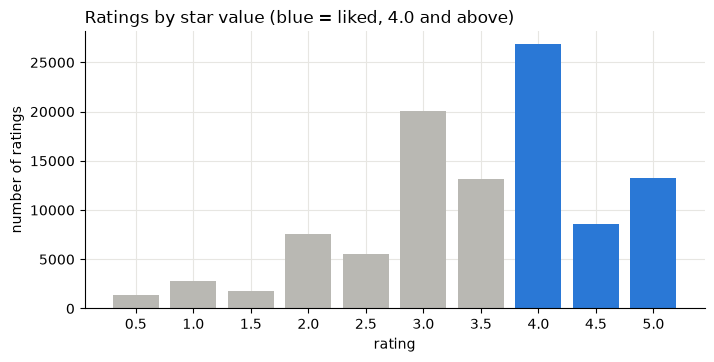

mean rating: 3.50
share of ratings >= 4.0: 48.2%


In [3]:
counts = ratings.rating.value_counts().sort_index()
colors = [BLUE if value >= LIKED else GRAY for value in counts.index]

fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values, color=colors, width=0.8)
ax.set_title("Ratings by star value (blue = liked, 4.0 and above)", loc="left")
ax.set_xlabel("rating")
ax.set_ylabel("number of ratings")
plt.show()

print(f"mean rating: {ratings.rating.mean():.2f}")
print(f"share of ratings >= {LIKED}: {(ratings.rating >= LIKED).mean():.1%}")

The mean rating is 3.5, so a rating of 3 is below this audience's average rather than neutral. Taking **4.0 and above as "liked"** splits the ratings almost in half (48% liked), which gives balanced classes for link prediction. The same threshold is used everywhere: the similarity input, the users' communities, the recommendation queries and the ML label.

### 1.3 Ratings per user and per movie

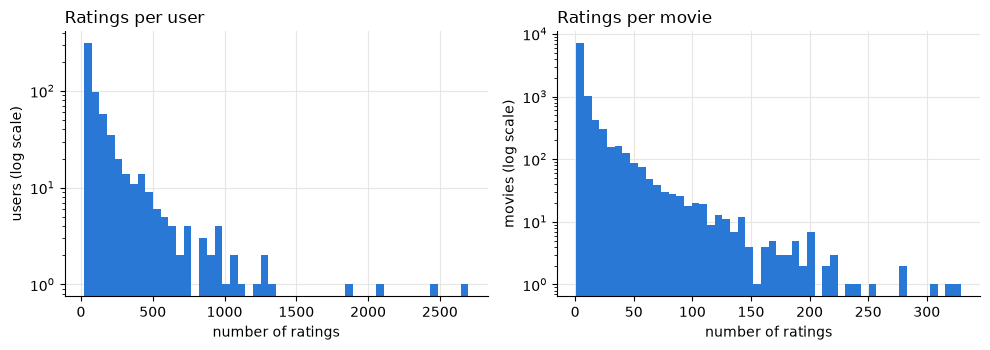

,per user,per movie
count,610.0,9724.0
mean,165.3,10.4
std,269.5,22.4
min,20.0,1.0
25%,35.0,1.0
50%,70.5,3.0
75%,168.0,9.0
max,2698.0,329.0


In [4]:
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, series, label in ((axes[0], per_user, "user"), (axes[1], per_movie, "movie")):
    ax.hist(series, bins=50, color=BLUE, log=True)
    ax.set_title(f"Ratings per {label}", loc="left")
    ax.set_xlabel("number of ratings")
    ax.set_ylabel(f"{label}s (log scale)")
plt.tight_layout()
plt.show()

pd.DataFrame({"per user": per_user.describe(), "per movie": per_movie.describe()}).round(1)

Both distributions have a long tail. Every user has at least 20 ratings (a property of how GroupLens built the dataset), but the median movie has only **3 ratings** and a third of the movies have exactly one. Similarity computed from one or two shared raters is noise: two movies that share their only rater would score a perfect 1.0.

### 1.4 Choosing the similarity cutoff

In [5]:
likes = ratings[ratings.rating >= LIKED]
likes_per_movie = likes.groupby("movieId").size()

rows = []
for cutoff in (1, 2, 3, 5, 10, 20):
    kept = likes_per_movie[likes_per_movie >= cutoff]
    rows.append({
        "min likes per movie": cutoff,
        "movies kept": len(kept),
        "share of all likes covered": f"{kept.sum() / likes_per_movie.sum():.0%}",
    })
pd.DataFrame(rows)

,min likes per movie,movies kept,share of all likes covered
0,1,6298,100%
1,2,3722,95%
2,3,2810,91%
3,5,1956,85%
4,10,1182,74%
5,20,605,58%


With a cutoff of **5 likes**, Node Similarity compares about 2,000 movies and still covers 85% of all "liked" ratings. Lower cutoffs mostly add movies whose similarity would rest on one or two people; higher cutoffs start dropping a large share of the signal. This value becomes the `degreeCutoff` of Node Similarity in `scripts/run_gds.py`.

### 1.5 Genres: nodes, a list property, or both

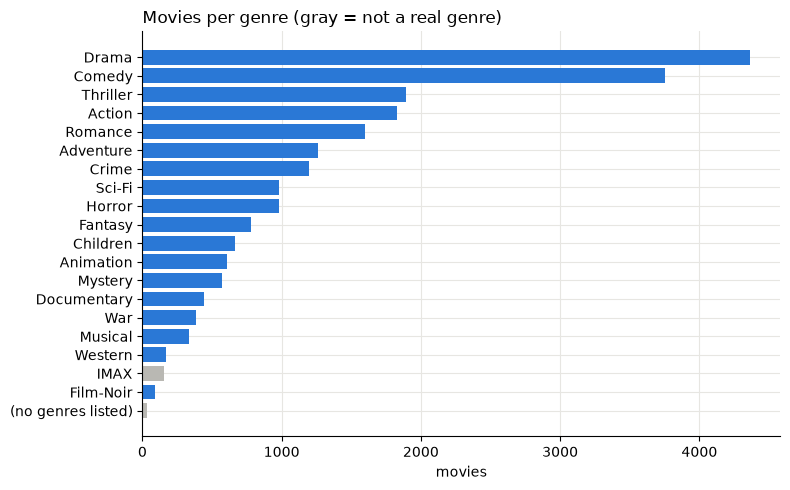

distinct genre values: 20
genres per movie: mean 2.3, max 10


In [6]:
genres = movies.genres.str.split("|").explode()
genre_counts = genres.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = [GRAY if g in ("IMAX", "(no genres listed)") else BLUE for g in genre_counts.index]
ax.barh(genre_counts.index, genre_counts.values, color=colors)
ax.set_title("Movies per genre (gray = not a real genre)", loc="left")
ax.set_xlabel("movies")
plt.tight_layout()
plt.show()

genres_per_movie = movies.genres.str.split("|").str.len()
print(f"distinct genre values: {genres.nunique()}")
print(f"genres per movie: mean {genres_per_movie.mean():.1f}, max {genres_per_movie.max()}")

There are only 20 genre values, and each movie has two on average. Two consequences for the model:

* **Genre nodes** are cheap (about 20 nodes) and turn "movies that share a genre" into a traversal, which GDS and the explanation paths of the *why* endpoint can use.
* A **`genres` list on Movie** answers "is this movie a comedy?" without leaving the node, which is the cheap filter used inside recommendation queries.

We keep both and treat the duplication as a deliberate denormalisation, written once by the seed script. Two values need special handling: `(no genres listed)` gets no Genre node and an empty list, and `IMAX` is a screening format rather than a genre; it is kept as MovieLens defines it, but documented.

### 1.6 Titles: years, articles and duplicates

In [7]:
year = movies.title.str.extract(r"\((\d{4})(?:[–-]\d{4})?\)\s*$")[0]
article_suffix = movies.title.str.contains(r", (?:The|A|An) \(", regex=True)
duplicated = movies[movies.title.duplicated(keep=False)].merge(links, on="movieId")

pd.Series({
    "titles without a year": int(year.isna().sum()),
    "titles with a trailing space": int((movies.title != movies.title.str.strip()).sum()),
    "titles with a moved article (\"Matrix, The\")": int(article_suffix.sum()),
    "titles shared by two movieIds": int(movies.title.duplicated().sum()),
    "year range": f"{int(year.dropna().astype(int).min())}–{int(year.dropna().astype(int).max())}",
}).to_frame("value")

,value
titles without a year,12
titles with a trailing space,11
"titles with a moved article (""Matrix, The"")",1822
titles shared by two movieIds,5
year range,1902–2018


In [8]:
duplicated[["movieId", "title", "imdbId", "tmdbId"]].sort_values("title")

,movieId,title,imdbId,tmdbId
2,6003,Confessions of a Dangerous Mind (2002),290538,4912.0
7,144606,Confessions of a Dangerous Mind (2002),270288,4912.0
0,838,Emma (1996),116191,3573.0
3,26958,Emma (1996),118308,12254.0
4,32600,Eros (2004),377059,NaN
8,147002,Eros (2004),343663,39850.0
1,2851,Saturn 3 (1980),81454,NaN
9,168358,Saturn 3 (1980),79285,19761.0
5,34048,War of the Worlds (2005),407304,74.0
6,64997,War of the Worlds (2005),449040,34812.0


What the seed script has to clean:

* The year lives inside the title, sometimes as a range (`(2006–2007)` for a TV series) and sometimes not at all: `year` is parsed out and left empty when absent.
* Titles such as `Matrix, The (1999)` are stored as `The Matrix`, which is how people (and the LLM in `/api/ask`) write them.
* **Titles are not unique.** The five duplicates have different IMDb ids, so they are different films (for example the 1996 *Emma* film and the TV adaptation). `movieId` is the only key; there is no uniqueness constraint on `title`, and a title lookup can return several movies.

### 1.7 Time span (for the temporal split)

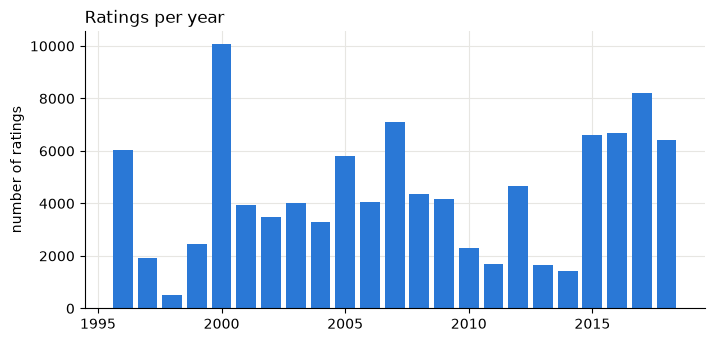

first rating: 1996-03-29, last rating: 2018-09-24
80% of ratings are older than 2016-03-22


In [9]:
rated_at = pd.to_datetime(ratings.timestamp, unit="s")
per_year = rated_at.dt.year.value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(per_year.index, per_year.values, color=BLUE, width=0.8)
ax.set_title("Ratings per year", loc="left")
ax.set_ylabel("number of ratings")
plt.show()

print(f"first rating: {rated_at.min():%Y-%m-%d}, last rating: {rated_at.max():%Y-%m-%d}")
print(f"80% of ratings are older than {rated_at.quantile(0.8):%Y-%m-%d}")

Ratings span 1996 to September 2018. Two consequences:

* **"Recent" is relative to the last rating in the data**, not to today: a "last 30 days" window ending in 2026 would be empty. The trending endpoint has to anchor its window on the maximum timestamp.
* The link-prediction model is trained on older ratings and tested on newer ones. Splitting at the 80th percentile of timestamps puts the cutoff around March 2016.

### 1.8 Tags and external ids

In [10]:
normalised = tags.tag.str.strip().str.lower()
pd.Series({
    "tag applications": len(tags),
    "users who tagged": tags.userId.nunique(),
    "distinct tags (raw)": tags.tag.nunique(),
    "distinct tags (lower-cased)": normalised.nunique(),
    "movies with at least one tag": tags.movieId.nunique(),
    "movies missing a tmdbId": int(links.tmdbId.isna().sum()),
}).to_frame("value")

,value
tag applications,3683
users who tagged,58
distinct tags (raw),1589
distinct tags (lower-cased),1475
movies with at least one tag,1572
movies missing a tmdbId,8


Tags come from only 58 of the 610 users and are mostly one-off free text, with case variants of the same tag. They are stored as `(:User)-[:TAGGED {tag, timestamp}]->(:Movie)` with the tag lower-cased. This keeps the triple *who tagged which movie with what*. The alternative `(:User)-[:TAGGED]->(:Tag)-[:TAG_OF]->(:Movie)` was rejected because it loses that triple: once a tag node is shared, you can no longer tell which movie a given user tagged.

A few movies have no `tmdbId`, so that property is optional on Movie.

### 1.9 Decisions supported by this section

| Observation | Decision |
|---|---|
| Fewer than 2% of user–movie pairs are rated | Ratings are `RATED` relationships carrying `rating` and `timestamp` |
| 48% of ratings are 4.0 or higher | "Liked" means a rating of 4.0 or higher, everywhere |
| Median movie has 3 ratings | Node Similarity uses `degreeCutoff = 5` likes (2,000 movies, 85% of likes) |
| 20 genre values, about 2 per movie | Genre nodes and a `genres` list on Movie; `(no genres listed)` gives no node |
| Year embedded in the title, sometimes missing | `year` parsed out, nullable; title stored without it, article moved back to the front |
| Five titles shared by different films | `movieId` is the only key; no uniqueness constraint on `title` |
| Ratings end in September 2018 | "Recent" is measured from the last rating; temporal split at the 80th percentile |
| Tags are sparse free text from 58 users | `TAGGED` relationship with a lower-cased `tag` property; no Tag nodes |